##  Regresión Multivariada 
### Selección de variables predictoras

Dr. Hugo García Tecocoatzi

In [1]:
#  Importar bibliotecas necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics
from sklearn.feature_selection import f_regression, SelectKBest

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

Vamos a generar datos sintéticos para la actividad:

In [2]:
#  Simulamos un problema de bienes raíces
np.random.seed(42)
n = 200

# Variables predictoras
Tamaño = np.random.randn(n) * 10 + 50           # Tamaño en m²
Habitaciones = Tamaño + np.random.randn(n) * 3  # Número de habitaciones (correlacionado)
Antigüedad = np.random.randn(n) * 5 + 20        # Antigüedad en años
Ubicación = np.random.randn(n) * 3 + 5          # Calidad de ubicación (1-10)

# Variable respuesta (precio)
Precio = 500 + 25*Tamaño + 15*Habitaciones - 8*Antigüedad + 30*Ubicación + np.random.randn(n)*50

# Crear DataFrame
df = pd.DataFrame({
    'Tamaño': Tamaño,
    'Habitaciones': Habitaciones,
    'Antigüedad': Antigüedad,
    'Ubicación': Ubicación,
    'Precio': Precio
})


print(f"Forma del dataset: {df.shape}")
print("\nPrimeras 5 filas:")
df.head()

Forma del dataset: (200, 5)

Primeras 5 filas:


,Tamaño,Habitaciones,Antigüedad,Ubicación,Precio
0,54.967142,56.040504,12.027862,7.270966,2883.606365
1,48.617357,50.299711,17.003125,2.233504,2375.107469
2,56.476885,59.726039,20.026218,7.608818,2880.673545
3,65.230299,68.391705,20.234903,9.066914,3243.647454
4,47.658466,43.525458,17.749673,6.240305,2367.830477


In [3]:
# Estadísticas descriptivas
print("ESTADÍSTICAS DESCRIPTIVAS\n")
print(df.describe().round(2))

ESTADÍSTICAS DESCRIPTIVAS

       Tamaño  Habitaciones  Antigüedad  Ubicación   Precio
count  200.00        200.00      200.00     200.00   200.00
mean    49.59         49.85       19.57       5.03  2488.20
std      9.31         10.03        4.97       3.06   403.41
min     23.80         20.86        7.64      -3.09  1203.80
25%     42.95         43.03       16.03       2.88  2199.68
50%     49.96         50.35       19.61       5.07  2494.96
75%     55.01         55.75       22.86       7.06  2744.40
max     77.20         77.07       35.39      12.90  3663.00


In [4]:
# Matriz de correlación detallada
print("\nMATRIZ DE CORRELACIÓN\n")
print(df.corr().round(3))


MATRIZ DE CORRELACIÓN

              Tamaño  Habitaciones  Antigüedad  Ubicación  Precio
Tamaño         1.000         0.956      -0.134      0.065   0.958
Habitaciones   0.956         1.000      -0.134      0.031   0.936
Antigüedad    -0.134        -0.134       1.000      0.106  -0.199
Ubicación      0.065         0.031       0.106      1.000   0.287
Precio         0.958         0.936      -0.199      0.287   1.000


### Preguntas

**1. ¿Qué variables tienen mayor correlación con el Precio?**
- **Tamaño(0.958):** Presenta una correlación muy alta, el precio aumenta casi linealmente con los metros cuadrados de la vivienda.
- **Habitaciones(0.936):** Ocupando el puesto 2 en correlación con el precio, nos muestra como es un alto indicador en el precio de la casa, siendo ligeramente menor al tamaño, que si bien no es nueva información arrastra la que ya conocíamos.

**2. ¿Hay variables altamente correlacionadas entre sí? ¿Cuáles?**
- Si, siendo Tamaño y Habitaciones, pues cuentan con un r = 0.956, siendo este el par más problemático del dataset.

**3. ¿Cómo crees que afecta cada variable al precio?**
- **Tamaño (0.958):** Efecto positivo fuerte, más metros = más caro.
- **Habitaciones (0.936):** Positivo, pero resulta redundante, no aporta información independiente del tamaño.
- **Antugüedad (-0.199):** Se observa un efecto de depreciación, a más antiguedad el valor disminuye.
- **Ubicación (0.287):** Efecto positivo, a mejor zona = más caro.
- **Precio (1.000):** Es la variable respuesta, no se interpreta.

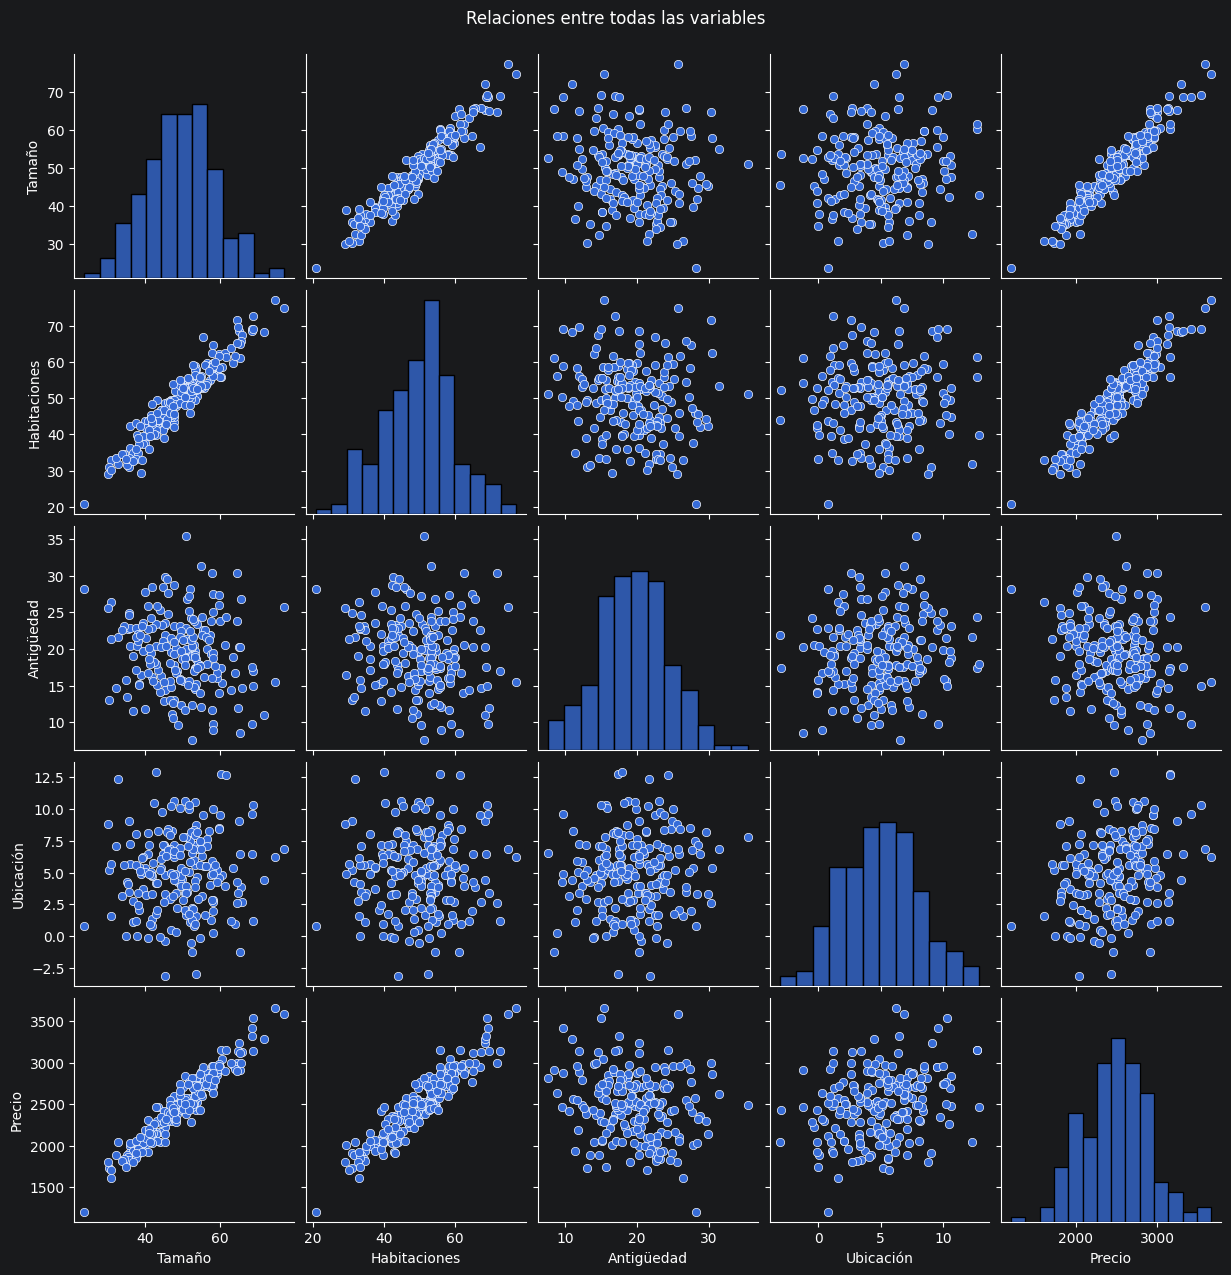

In [5]:
# Pairplot de variables
sns.pairplot(df)
plt.suptitle('Relaciones entre todas las variables', y=1.02)
plt.show()

In [6]:
#  Dividir datos en entrenamiento y prueba
X = df.drop('Precio', axis=1)
y = df['Precio']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print(f"Tamaño de entrenamiento: {X_train.shape[0]} muestras")
print(f"Tamaño de prueba: {X_test.shape[0]} muestras")

Tamaño de entrenamiento: 140 muestras
Tamaño de prueba: 60 muestras


In [7]:
# Entrenar modelo de regresión lineal con todas las variables
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# Mostrar coeficientes
coeficientes = pd.DataFrame({
    'Variable': X.columns,
    'Coeficiente': modelo.coef_
})
print("=== COEFICIENTES DEL MODELO ===\n")
print(coeficientes)
print(f"\nIntercept (término constante): {modelo.intercept_:.4f}")

=== COEFICIENTES DEL MODELO ===

       Variable  Coeficiente
0        Tamaño    28.191932
1  Habitaciones    12.110154
2    Antigüedad    -7.294327
3     Ubicación    32.566862

Intercept (término constante): 467.3919


In [8]:
# Evaluar modelo completo
y_pred = modelo.predict(X_test)

MAE = metrics.mean_absolute_error(y_test, y_pred)
MSE = metrics.mean_squared_error(y_test, y_pred)
RMSE = np.sqrt(MSE)
R2 = metrics.r2_score(y_test, y_pred)

print("=== MÉTRICAS DE EVALUACIÓN ===\n")
print(f"Error Absoluto Medio (MAE): {MAE:.4f}")
print(f"Error Cuadrático Medio (MSE): {MSE:.4f}")
print(f"Raíz del Error Cuadrático Medio (RMSE): {RMSE:.4f}")
print(f"R² (Coeficiente de Determinación): {R2:.4f}")

=== MÉTRICAS DE EVALUACIÓN ===

Error Absoluto Medio (MAE): 39.1850
Error Cuadrático Medio (MSE): 2274.3596
Raíz del Error Cuadrático Medio (RMSE): 47.6902
R² (Coeficiente de Determinación): 0.9828


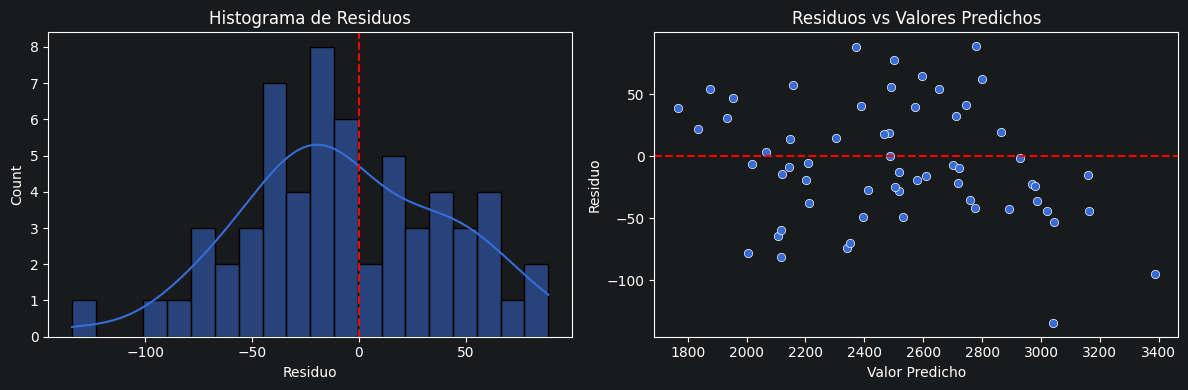

Media de residuos: -6.4355
Desviación estándar de residuos: 47.6528


In [9]:
# Análisis de residuos
residuos = y_test - y_pred

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.histplot(residuos, kde=True, bins=20)
plt.axvline(x=0, color='r', linestyle='--')
plt.title('Histograma de Residuos')
plt.xlabel('Residuo')

plt.subplot(1, 2, 2)
sns.scatterplot(x=y_pred, y=residuos)
plt.axhline(y=0, color='r', linestyle='--')
plt.title('Residuos vs Valores Predichos')
plt.xlabel('Valor Predicho')
plt.ylabel('Residuo')

plt.tight_layout()
plt.show()

print(f"Media de residuos: {residuos.mean():.4f}")
print(f"Desviación estándar de residuos: {residuos.std():.4f}")

In [10]:
# Cálculo del VIF (Factor de Inflación de la Varianza)
X_constant = sm.add_constant(X)
vif_data = pd.DataFrame()
vif_data["Variable"] = X_constant.columns
vif_data["VIF"] = [variance_inflation_factor(X_constant.values, i) 
                   for i in range(X_constant.shape[1])]

print("=== FACTOR DE INFLACIÓN DE LA VARIANZA (VIF) ===\n")
print(vif_data)
print("\n Recuerda:")
print("- VIF > 5: indica alta multicolinealidad")
print("- VIF > 10: indica multicolinealidad severa")

=== FACTOR DE INFLACIÓN DE LA VARIANZA (VIF) ===

       Variable        VIF
0         const  52.311219
1        Tamaño  11.780300
2  Habitaciones  11.727624
3    Antigüedad   1.032297
4     Ubicación   1.029735

 Recuerda:
- VIF > 5: indica alta multicolinealidad
- VIF > 10: indica multicolinealidad severa


In [11]:
#  Selección hacia adelante (Forward Selection)
def forward_selection(X, y, threshold=0.05):
    """
    Selección de variables hacia adelante basada en p-valor
    """
    included = []
    while True:
        changed = False
        excluded = list(set(X.columns) - set(included))
        new_pval = pd.Series(index=excluded, dtype=float)
        
        for new_col in excluded:
            model = sm.OLS(y, sm.add_constant(pd.DataFrame(X[included + [new_col]]))).fit()
            new_pval[new_col] = model.pvalues[new_col]
        
        best_pval = new_pval.min()
        if best_pval < threshold:
            best_feature = new_pval.idxmin()
            included.append(best_feature)
            changed = True
        
        if not changed:
            break
    
    return included

print("=== SELECCIÓN HACIA ADELANTE ===\n")
variables_seleccionadas = forward_selection(X, y)
print(f"Variables seleccionadas: {variables_seleccionadas}")

=== SELECCIÓN HACIA ADELANTE ===

Variables seleccionadas: ['Tamaño', 'Ubicación', 'Antigüedad', 'Habitaciones']


In [12]:
# Comparación de modelos con diferentes variables
print("=== COMPARACIÓN DE MODELOS ===\n")

combinaciones = [
    ['Tamaño'],
    ['Tamaño', 'Habitaciones'],
    ['Tamaño', 'Habitaciones', 'Antigüedad'],
    ['Tamaño', 'Habitaciones', 'Antigüedad', 'Ubicación'],
    variables_seleccionadas
]

nombres_combinaciones = [
    'Modelo 1: Tamaño',
    'Modelo 2: Tamaño + Habitaciones',
    'Modelo 3: Tamaño + Habitaciones + Antigüedad',
    'Modelo 4: Modelo completo',
    'Modelo 5: Variables seleccionadas (Forward)'
]

for nombre, vars_list in zip(nombres_combinaciones, combinaciones):
    X_sel = sm.add_constant(X[vars_list])
    model = sm.OLS(y, X_sel).fit()
    
    print(f"📊 {nombre}")
    print(f"  Variables: {vars_list}")
    print(f"  R² = {model.rsquared:.4f}")
    print(f"  R² ajustado = {model.rsquared_adj:.4f}")
    print(f"  AIC = {model.aic:.2f}")
    print(f"  BIC = {model.bic:.2f}")
    print()

=== COMPARACIÓN DE MODELOS ===

📊 Modelo 1: Tamaño
  Variables: ['Tamaño']
  R² = 0.9178
  R² ajustado = 0.9174
  AIC = 2470.82
  BIC = 2477.41

📊 Modelo 2: Tamaño + Habitaciones
  Variables: ['Tamaño', 'Habitaciones']
  R² = 0.9228
  R² ajustado = 0.9220
  AIC = 2460.37
  BIC = 2470.26

📊 Modelo 3: Tamaño + Habitaciones + Antigüedad
  Variables: ['Tamaño', 'Habitaciones', 'Antigüedad']
  R² = 0.9276
  R² ajustado = 0.9265
  AIC = 2449.43
  BIC = 2462.63

📊 Modelo 4: Modelo completo
  Variables: ['Tamaño', 'Habitaciones', 'Antigüedad', 'Ubicación']
  R² = 0.9866
  R² ajustado = 0.9863
  AIC = 2113.96
  BIC = 2130.45

📊 Modelo 5: Variables seleccionadas (Forward)
  Variables: ['Tamaño', 'Ubicación', 'Antigüedad', 'Habitaciones']
  R² = 0.9866
  R² ajustado = 0.9863
  AIC = 2113.96
  BIC = 2130.45



In [13]:
# Análisis detallado del mejor modelo
print("=== MEJOR MODELO SEGÚN FORWARD SELECTION ===\n")

X_sel = sm.add_constant(X[variables_seleccionadas])
modelo_final = sm.OLS(y, X_sel).fit()
print(modelo_final.summary())

=== MEJOR MODELO SEGÚN FORWARD SELECTION ===

                            OLS Regression Results                            
Dep. Variable:                 Precio   R-squared:                       0.987
Model:                            OLS   Adj. R-squared:                  0.986
Method:                 Least Squares   F-statistic:                     3591.
Date:                Thu, 17 Sep 2026   Prob (F-statistic):          2.30e-181
Time:                        22:15:40   Log-Likelihood:                -1052.0
No. Observations:                 200   AIC:                             2114.
Df Residuals:                     195   BIC:                             2130.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
co

In [14]:
# Evaluación del mejor modelo en test
X_train_sel = X_train[variables_seleccionadas]
X_test_sel = X_test[variables_seleccionadas]

modelo_sel = LinearRegression()
modelo_sel.fit(X_train_sel, y_train)

y_pred_sel = modelo_sel.predict(X_test_sel)

MAE_sel = metrics.mean_absolute_error(y_test, y_pred_sel)
MSE_sel = metrics.mean_squared_error(y_test, y_pred_sel)
RMSE_sel = np.sqrt(MSE_sel)
R2_sel = metrics.r2_score(y_test, y_pred_sel)

print("=== COMPARACIÓN DE RENDIMIENTO ===\n")
print("Modelo Completo vs Modelo Seleccionado:")

print(f"\nModelo Completo (todas las variables):")
print(f"  MAE: {MAE:.4f}")
print(f"  RMSE: {RMSE:.4f}")
print(f"  R²: {R2:.4f}")

print(f"\nModelo Seleccionado ({variables_seleccionadas}):")
print(f"  MAE: {MAE_sel:.4f}")
print(f"  RMSE: {RMSE_sel:.4f}")
print(f"  R²: {R2_sel:.4f}")

=== COMPARACIÓN DE RENDIMIENTO ===

Modelo Completo vs Modelo Seleccionado:

Modelo Completo (todas las variables):
  MAE: 39.1850
  RMSE: 47.6902
  R²: 0.9828

Modelo Seleccionado (['Tamaño', 'Ubicación', 'Antigüedad', 'Habitaciones']):
  MAE: 39.1850
  RMSE: 47.6902
  R²: 0.9828


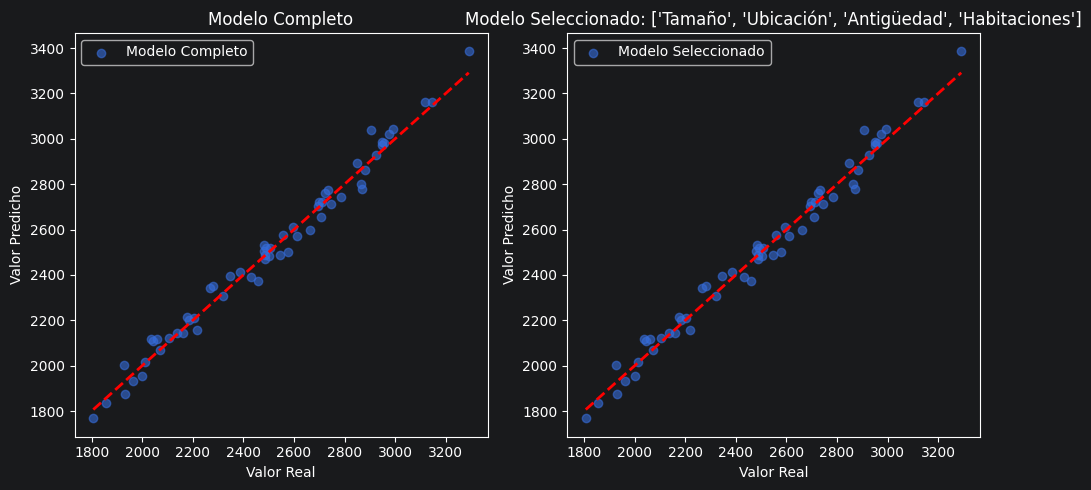

In [15]:
# Visualización del modelo seleccionado
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred, alpha=0.6, label='Modelo Completo')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Valor Real')
plt.ylabel('Valor Predicho')
plt.title('Modelo Completo')
plt.legend()

plt.subplot(1, 2, 2)
plt.scatter(y_test, y_pred_sel, alpha=0.6, label='Modelo Seleccionado')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Valor Real')
plt.ylabel('Valor Predicho')
plt.title(f'Modelo Seleccionado: {variables_seleccionadas}')
plt.legend()

plt.tight_layout()
plt.show()

## Actividad Final

Utiliza este notebook para ver qué varibles debes eliminar de la base de datos de Real Estate

In [19]:
# Cargamos y exploramos el dataset 🤠

# Carga de datos
df = pd.read_csv('Realestate.csv')
df = df.drop(columns=['No'])  # índice, no predictor
df.columns = ['Fecha', 'Antiguedad', 'Dist_MRT', 'Tiendas',
                'Latitud', 'Longitud', 'Precio']

print(f"Forma del dataset: {df.shape}")
print(f"Valores nulos: {df.isnull().sum().sum()}")
df.head()

Forma del dataset: (414, 7)
Valores nulos: 0


,Fecha,Antiguedad,Dist_MRT,Tiendas,Latitud,Longitud,Precio
0,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


In [20]:
print("ESTADÍSTICAS DESCRIPTIVAS\n")
print(df.describe().round(3))

ESTADÍSTICAS DESCRIPTIVAS

          Fecha  Antiguedad  Dist_MRT  Tiendas  Latitud  Longitud   Precio
count   414.000     414.000   414.000  414.000  414.000   414.000  414.000
mean   2013.149      17.713  1083.886    4.094   24.969   121.533   37.980
std       0.282      11.392  1262.110    2.946    0.012     0.015   13.606
min    2012.667       0.000    23.383    0.000   24.932   121.474    7.600
25%    2012.917       9.025   289.325    1.000   24.963   121.528   27.700
50%    2013.167      16.100   492.231    4.000   24.971   121.539   38.450
75%    2013.417      28.150  1454.279    6.000   24.977   121.543   46.600
max    2013.583      43.800  6488.021   10.000   25.015   121.566  117.500



MATRIZ DE CORRELACIÓN

            Fecha  Antiguedad  Dist_MRT  Tiendas  Latitud  Longitud  Precio
Fecha       1.000       0.018     0.061    0.010    0.035    -0.041   0.087
Antiguedad  0.018       1.000     0.026    0.050    0.054    -0.049  -0.211
Dist_MRT    0.061       0.026     1.000   -0.603   -0.591    -0.806  -0.674
Tiendas     0.010       0.050    -0.603    1.000    0.444     0.449   0.571
Latitud     0.035       0.054    -0.591    0.444    1.000     0.413   0.546
Longitud   -0.041      -0.049    -0.806    0.449    0.413     1.000   0.523
Precio      0.087      -0.211    -0.674    0.571    0.546     0.523   1.000


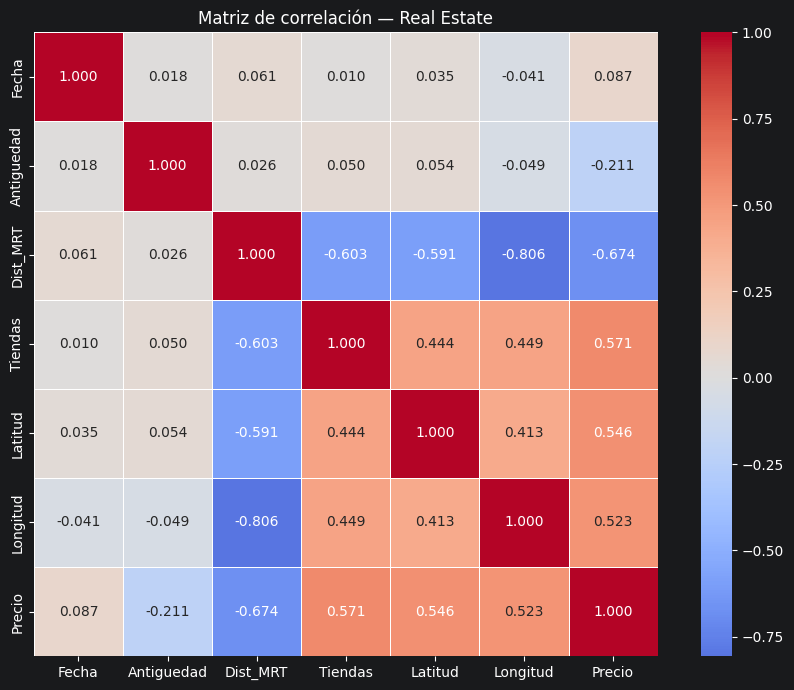

In [21]:
# Matriz de correlación
print("\nMATRIZ DE CORRELACIÓN\n")
print(df.corr().round(3))

plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt='.3f', cmap='coolwarm', center=0,
            square=True, linewidths=.5)
plt.title('Matriz de correlación — Real Estate')
plt.tight_layout()
plt.show()

# Lectura
De la matriz de correlación, podemos observar que Dist_MRT es más fuerte y con signo negativo: "mientras más lejos del metro, más barata es la casa", siendo Tiendas, Latitud y Longitud la misma idea medida de formas distintas, se refieren a que tan céntrica está la casa.

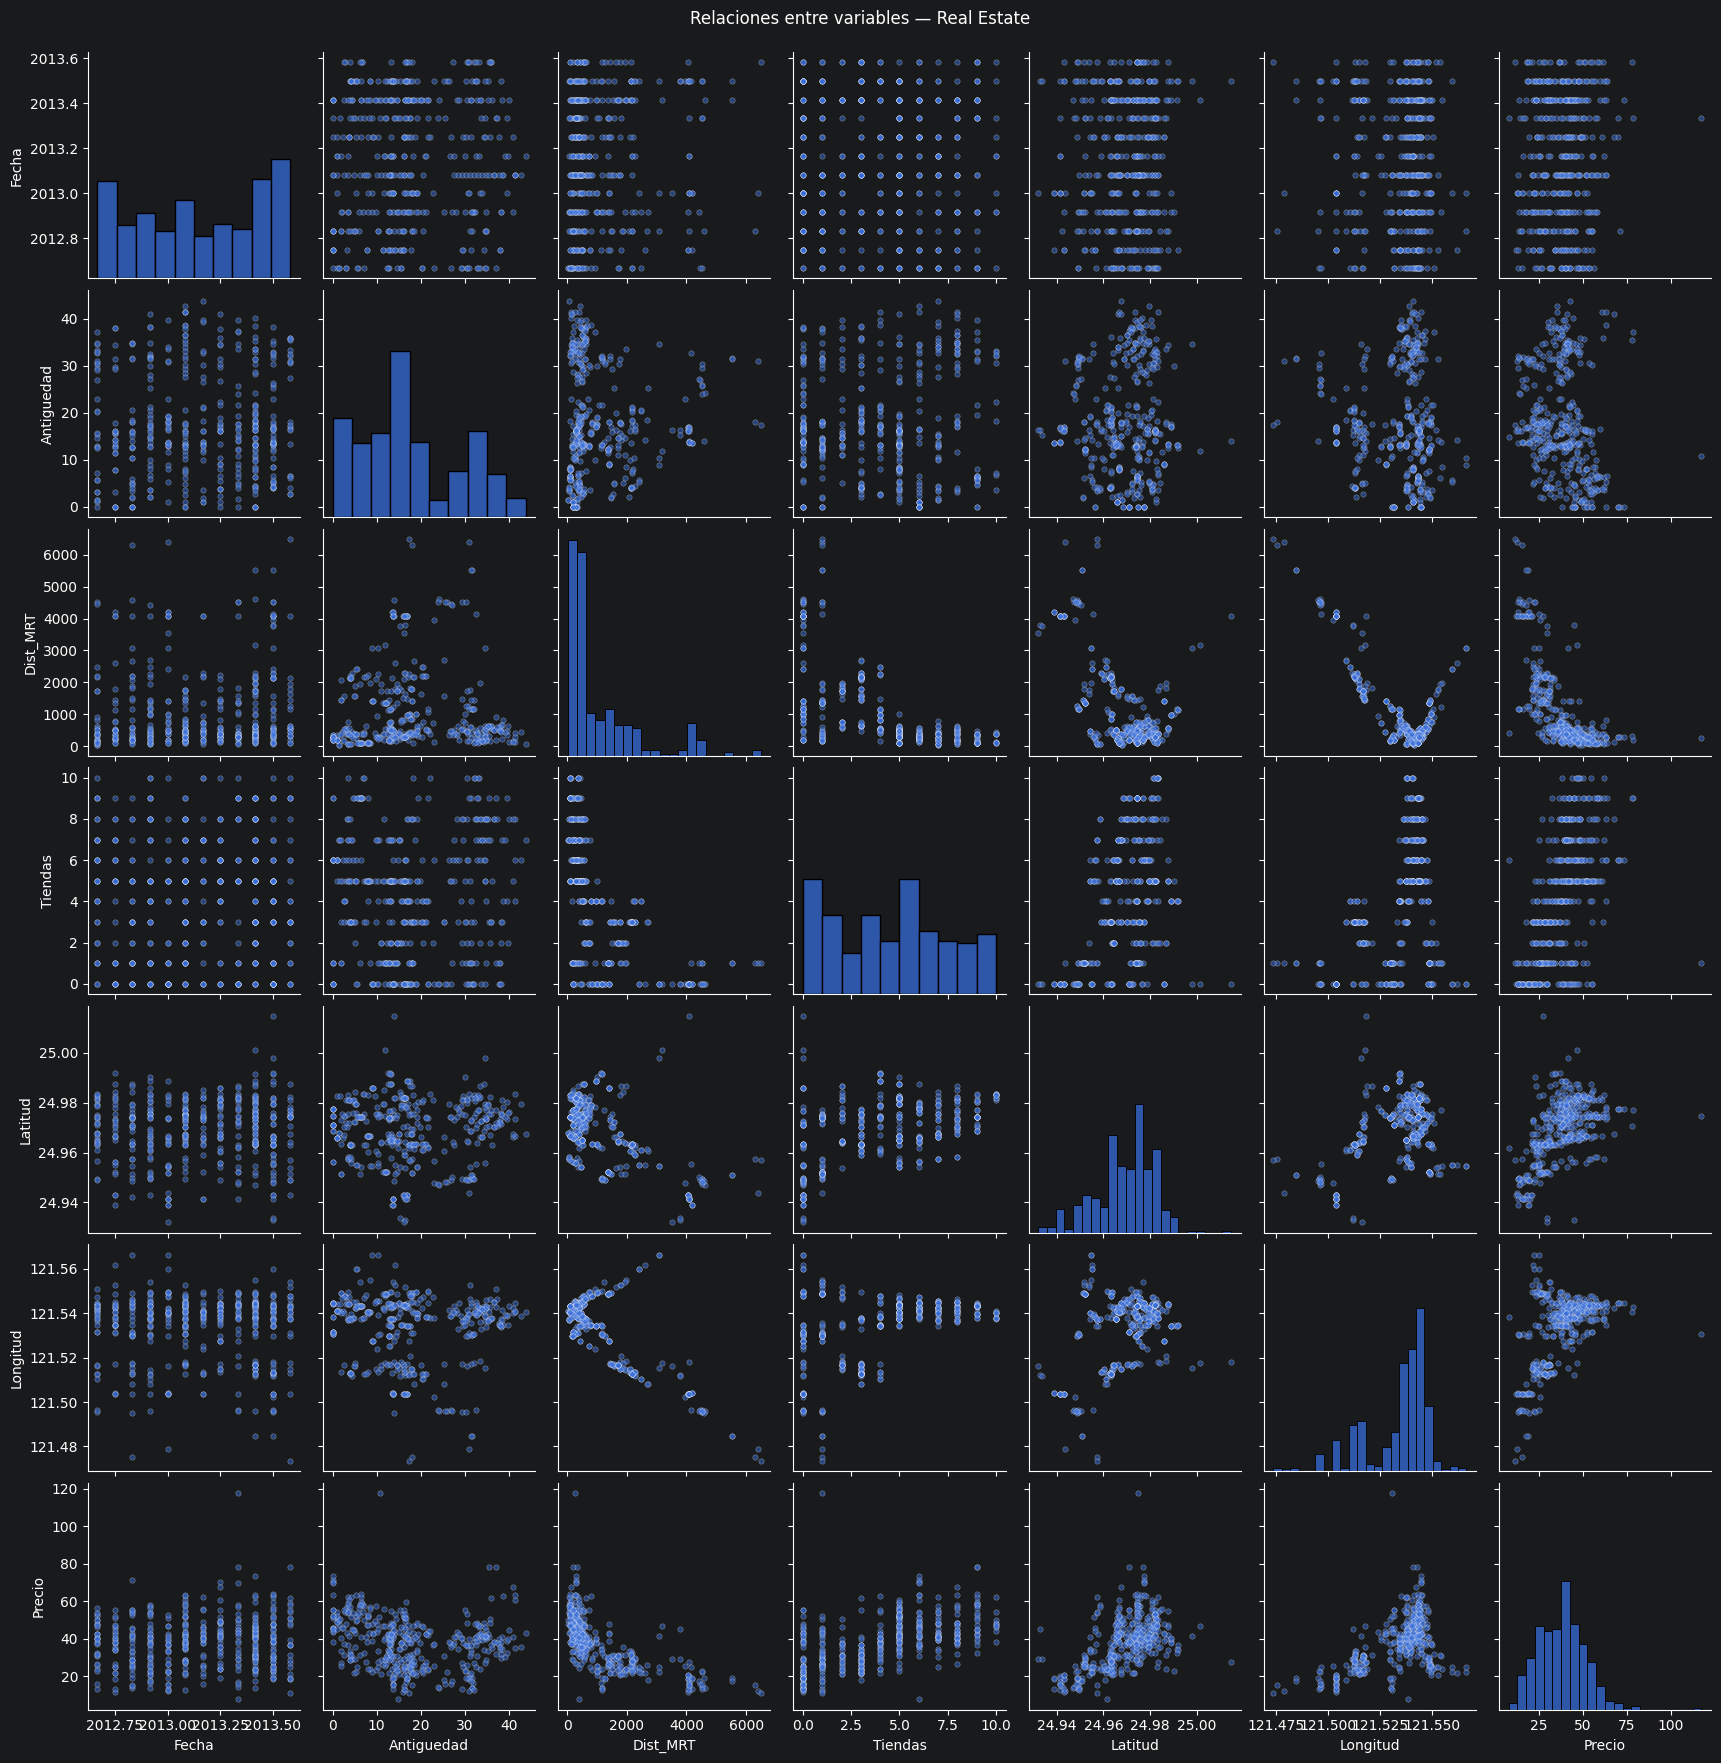

In [22]:
# Pairplot
sns.pairplot(df, plot_kws={'alpha': 0.5, 's': 15})
plt.suptitle('Relaciones entre variables — Real Estate', y=1.01)
plt.show()

In [23]:
# Diagnóstico de miltucolinealidad 🤠
Xre = df.drop('Precio', axis=1)
yre = df['Precio']

Xre_const = sm.add_constant(Xre)
vif_re = pd.DataFrame()
vif_re["Variable"] = Xre_const.columns
vif_re["VIF"] = [variance_inflation_factor(Xre_const.values, i)
                 for i in range(Xre_const.shape[1])]

print("=== VIF — MODELO COMPLETO ===\n")
print(vif_re.round(3))
print("\n- VIF > 5: alta multicolinealidad")
print("- VIF > 10: multicolinealidad severa")

=== VIF — MODELO COMPLETO ===

     Variable           VIF
0       const  2.422512e+08
1       Fecha  1.015000e+00
2  Antiguedad  1.014000e+00
3    Dist_MRT  4.323000e+00
4     Tiendas  1.617000e+00
5     Latitud  1.610000e+00
6    Longitud  2.926000e+00

- VIF > 5: alta multicolinealidad
- VIF > 10: multicolinealidad severa


In [24]:
# Modelo completo con statsmodels (para ver los p-valores)
modelo_completo_re = sm.OLS(yre, Xre_const).fit()
print(modelo_completo_re.summary())

                            OLS Regression Results                            
Dep. Variable:                 Precio   R-squared:                       0.582
Model:                            OLS   Adj. R-squared:                  0.576
Method:                 Least Squares   F-statistic:                     94.59
Date:                Thu, 17 Sep 2026   Prob (F-statistic):           4.86e-74
Time:                        22:16:51   Log-Likelihood:                -1487.0
No. Observations:                 414   AIC:                             2988.
Df Residuals:                     407   BIC:                             3016.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1.444e+04   6775.671     -2.131      0.0

# Diagnóstico del modelo
**VIF:** Dist_MRT = 4.32 y Longitud = 2.93 son los más altos, sin embrgo ninguno cruza el umbral de 5, es decir, el VIF por sí solo no basta para eliminar nada aquí, el problema se ve mejor en los p-valores.

Longitud es la única variable que no aporta nada: p = 0.798, imposible rechazar H_0: B = 0, y fijándonos en el signo, su correlación simple con el Precio es +0.523 (positiva), pero dentro del modelo su coeficiente sale negativo; ese cambio de signo es la firma clásica de la multicolinealidad: Dist_MRT ya se llevó toda la información geográfica que Longitud aportaba (r = -0.806 entre ellas), y lo que le queda a Longitud ahora es ruido.

Además cabe recalcar que el Cond. No. = 3.72e+07 del summary también lo confirma; statsmodels imprime la advertencia de multicolinealidad al final.

In [25]:
# Selección de variables 🤠

print("=== SELECCIÓN HACIA ADELANTE - REAL ESTATE ===\n")
vars_forward_re = forward_selection(Xre, yre)
print(f"Variables seleccionadas: {vars_forward_re}")
print(f"\nVariables descartadas: {list(set(Xre.columns) - set(vars_forward_re))}")

=== SELECCIÓN HACIA ADELANTE - REAL ESTATE ===

Variables seleccionadas: ['Dist_MRT', 'Tiendas', 'Antiguedad', 'Latitud', 'Fecha']

Variables descartadas: ['Longitud']


In [26]:
# Eliminación hacia atrás (backward elimination) - el camino inverso
def backward_elimination(X, y, threshold=0.05):
    incluidas = list(X.columns)
    while True:
        modelo = sm.OLS(y, sm.add_constant(X[incluidas])).fit()
        pvals = modelo.pvalues.iloc[1:]          # se excluye la constante
        peor_p = pvals.max()
        if peor_p > threshold:
            peor_var = pvals.idxmax()
            print(f"  Se elimina '{peor_var}' (p = {peor_p:.4f})")
            incluidas.remove(peor_var)
        else:
            break
    return incluidas

print("=== ELIMINACIÓN HACIA ATRÁS - REAL ESTATE ===\n")
vars_backward_re = backward_elimination(Xre, yre)
print(f"\nVariables finales: {vars_backward_re}")

=== ELIMINACIÓN HACIA ATRÁS - REAL ESTATE ===

  Se elimina 'Longitud' (p = 0.7983)

Variables finales: ['Fecha', 'Antiguedad', 'Dist_MRT', 'Tiendas', 'Latitud']


De ambos resultados se obtiene lo mismo, siendo que se queda todo, menos longitud.

In [27]:
# Comparación de modelos 🤠

print("=== COMPARACIÓN DE MODELOS - REAL ESTATE ===\n")

combinaciones_re = [
    ['Dist_MRT'],
    ['Dist_MRT', 'Antiguedad'],
    ['Dist_MRT', 'Antiguedad', 'Latitud'],
    ['Dist_MRT', 'Antiguedad', 'Latitud', 'Tiendas'],
    ['Dist_MRT', 'Antiguedad', 'Latitud', 'Tiendas', 'Fecha'],
    list(Xre.columns),
]

nombres_re = [
    'M1: Dist_MRT',
    'M2: + Antiguedad',
    'M3: + Latitud',
    'M4: + Tiendas',
    'M5: + Fecha  (SIN Longitud)',
    'M6: Modelo completo',
]

filas = []
for nombre, vlist in zip(nombres_re, combinaciones_re):
    m = sm.OLS(yre, sm.add_constant(Xre[vlist])).fit()
    filas.append({'Modelo': nombre, 'k': len(vlist),
                  'R2': round(m.rsquared, 4), 'R2_adj': round(m.rsquared_adj, 4),
                  'AIC': round(m.aic, 2), 'BIC': round(m.bic, 2)})

comparacion = pd.DataFrame(filas)
print(comparacion.to_string(index=False))

=== COMPARACIÓN DE MODELOS - REAL ESTATE ===

                     Modelo  k     R2  R2_adj     AIC     BIC
               M1: Dist_MRT  1 0.4538  0.4524 3089.07 3097.12
           M2: + Antiguedad  2 0.4911  0.4887 3061.72 3073.79
              M3: + Latitud  3 0.5316  0.5282 3029.43 3045.53
              M4: + Tiendas  4 0.5711  0.5669 2994.91 3015.04
M5: + Fecha  (SIN Longitud)  5 0.5823  0.5772 2985.99 3010.15
        M6: Modelo completo  6 0.5824  0.5762 2987.92 3016.11


In [28]:
# Evaluación de train y test (70/30)
Xre_train, Xre_test, yre_train, yre_test = train_test_split(
    Xre, yre, test_size=0.3, random_state=42
)

print("=== RENDIMIENTO EN TEST (70/30, random_state=42) ===\n")
filas_test = []
for nombre, vlist in zip(nombres_re, combinaciones_re):
    mo = LinearRegression().fit(Xre_train[vlist], yre_train)
    pred = mo.predict(Xre_test[vlist])
    filas_test.append({
        'Modelo': nombre,
        'MAE': round(metrics.mean_absolute_error(yre_test, pred), 4),
        'RMSE': round(np.sqrt(metrics.mean_squared_error(yre_test, pred)), 4),
        'R2_test': round(metrics.r2_score(yre_test, pred), 4),
    })

print(pd.DataFrame(filas_test).to_string(index=False))

=== RENDIMIENTO EN TEST (70/30, random_state=42) ===

                     Modelo    MAE   RMSE  R2_test
               M1: Dist_MRT 7.5195 9.7827   0.4277
           M2: + Antiguedad 6.8189 9.2801   0.4850
              M3: + Latitud 6.7333 9.0751   0.5075
              M4: + Tiendas 6.1281 8.5598   0.5618
M5: + Fecha  (SIN Longitud) 6.1424 8.5266   0.5652
        M6: Modelo completo 6.1848 8.5772   0.5601


In [30]:
# Modelo final 🤠

vars_finales = ['Fecha', 'Antiguedad', 'Dist_MRT', 'Tiendas', 'Latitud']

# VIF del modelo final
Xfin_const = sm.add_constant(Xre[vars_finales])
vif_fin = pd.DataFrame()
vif_fin["Variable"] = Xfin_const.columns
vif_fin["VIF"] = [variance_inflation_factor(Xfin_const.values, i)
                  for i in range(Xfin_const.shape[1])]

print("=== VIF - MODELO FINAL ===\n")
print(vif_fin.round(3))
print("\nEl VIF de Dist_MRT baja de 4.32 a 2.02 al quitar Longitud.")

=== VIF - MODELO FINAL ===

     Variable           VIF
0       const  5.529550e+07
1       Fecha  1.014000e+00
2  Antiguedad  1.013000e+00
3    Dist_MRT  2.017000e+00
4     Tiendas  1.611000e+00
5     Latitud  1.586000e+00

El VIF de Dist_MRT baja de 4.32 a 2.02 al quitar Longitud.


In [31]:
modelo_final_re = sm.OLS(yre, Xfin_const).fit()
print(modelo_final_re.summary())

                            OLS Regression Results                            
Dep. Variable:                 Precio   R-squared:                       0.582
Model:                            OLS   Adj. R-squared:                  0.577
Method:                 Least Squares   F-statistic:                     113.8
Date:                Thu, 17 Sep 2026   Prob (F-statistic):           4.47e-75
Time:                        22:19:46   Log-Likelihood:                -1487.0
No. Observations:                 414   AIC:                             2986.
Df Residuals:                     408   BIC:                             3010.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1.596e+04   3233.450     -4.936      0.0

In [33]:
# Comparación directa: completo vs final, en test
mod_comp = LinearRegression().fit(Xre_train, yre_train)
pred_comp = mod_comp.predict(Xre_test)

mod_fin = LinearRegression().fit(Xre_train[vars_finales], yre_train)
pred_fin = mod_fin.predict(Xre_test[vars_finales])

print("=== MODELO COMPLETO vs MODELO FINAL ===\n")
for etiqueta, p in [("Completo (6 variables)", pred_comp),
                    (f"Final ({len(vars_finales)} variables, sin Longitud)", pred_fin)]:
    print(f"{etiqueta}:")
    print(f"  MAE : {metrics.mean_absolute_error(yre_test, p):.4f}")
    print(f"  RMSE: {np.sqrt(metrics.mean_squared_error(yre_test, p)):.4f}")
    print(f"  R2  : {metrics.r2_score(yre_test, p):.4f}\n")

coef_fin = pd.DataFrame({'Variable': vars_finales, 'Coeficiente': mod_fin.coef_})
print("Coeficientes del modelo final:")
print(coef_fin)
print(f"\nIntercept: {mod_fin.intercept_:.4f}")

=== MODELO COMPLETO vs MODELO FINAL ===

Completo (6 variables):
  MAE : 6.1848
  RMSE: 8.5772
  R2  : 0.5601

Final (5 variables, sin Longitud):
  MAE : 6.1424
  RMSE: 8.5266
  R2  : 0.5652

Coeficientes del modelo final:
     Variable  Coeficiente
0       Fecha     5.805017
1  Antiguedad    -0.240770
2    Dist_MRT    -0.004579
3     Tiendas     1.086566
4     Latitud   243.341841

Intercept: -17719.6110


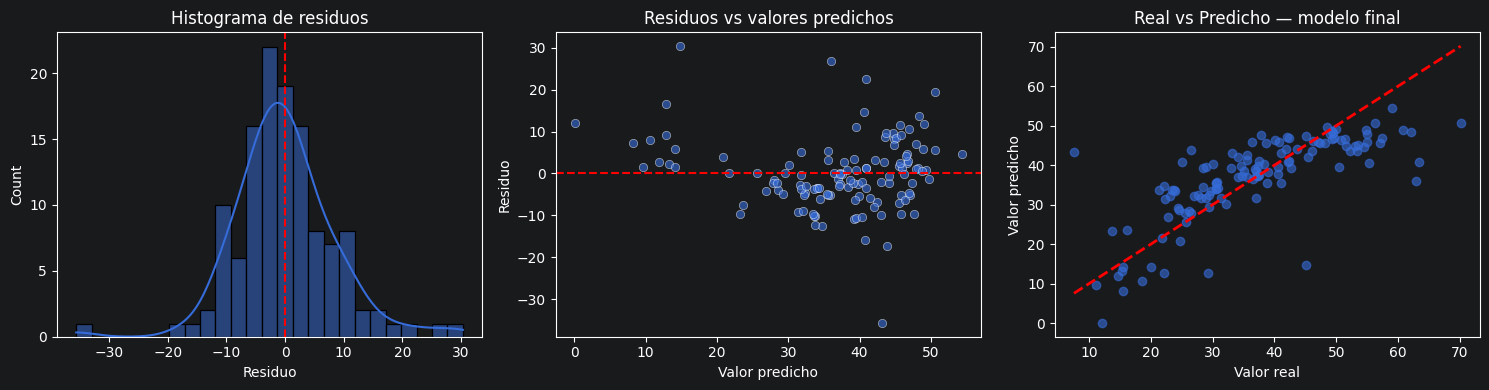

Media de residuos: -0.0124
Desv. estándar de residuos: 8.5609


In [34]:
# Para tenerlo elegante, un diagnóstico visual del modelo final!
residuos_fin = yre_test - pred_fin

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.histplot(residuos_fin, kde=True, bins=25)
plt.axvline(x=0, color='r', linestyle='--')
plt.title('Histograma de residuos')
plt.xlabel('Residuo')

plt.subplot(1, 3, 2)
sns.scatterplot(x=pred_fin, y=residuos_fin, alpha=0.6)
plt.axhline(y=0, color='r', linestyle='--')
plt.title('Residuos vs valores predichos')
plt.xlabel('Valor predicho'); plt.ylabel('Residuo')

plt.subplot(1, 3, 3)
plt.scatter(yre_test, pred_fin, alpha=0.6)
plt.plot([yre_test.min(), yre_test.max()], [yre_test.min(), yre_test.max()],
         'r--', lw=2)
plt.xlabel('Valor real'); plt.ylabel('Valor predicho')
plt.title('Real vs Predicho — modelo final')

plt.tight_layout()
plt.show()

print(f"Media de residuos: {residuos_fin.mean():.4f}")
print(f"Desv. estándar de residuos: {residuos_fin.std():.4f}")

# Conclusión

Eliminamos X6, Longitud es la única variable que sobra, además de quitar también No por ser sólo un índice no un predictor.
Esto porque los criterios apuntan a lo mismo:
1. p-valor: 0.798 en el modelo completo, la única variable no significativa.
2. Multicolinealidad: con un r = -0.806, su coeficiente cambia de signo entre la correlación simple y el modelo múltiple, siendo esta una señal de que la información de la misma se encuentra contenida en otra variable.
3. Criterios de información: R^2 ajustado, AIC  (2987.92 -> 2985.99), BIC  (3016.11 -> 3010.15).
4. Generalización: R^2 en test sube de 0.5601 a 0.5652 y el RMSE baja, siendo que el modelo con menos variables predice mejor fuera de muestra.

5. Además de que forward selection como backward elimination llegan de forma independiente al mismo conjunto.

In [36]:
# Paso final :D!
# Celda extra para volver el notebook en un .html

!jupyter nbconvert --to html "Actividad4.ipynb"

[NbConvertApp] Converting notebook Actividad4.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 6 image(s).
[NbConvertApp] Writing 1819184 bytes to Actividad4.html
